# Machine Learning Classification Workflow

This notebook trains and evaluates nonlinear machine learning models for dietary classification using mandibular second molar shape data.

It is written as a repository-ready version of the original machine learning workflow so that readers can download `Example_Data.csv` or use the GPA output and run the analysis themselves.

## What this notebook does

1. Loads Procrustes-aligned coordinate data.
2. Detects coordinate columns named `X1`, `Y1`, ..., `X23`, `Y23`.
3. Collapses the original dietary labels into the four manuscript categories and uses the collapsed dietary category as the classification target.
4. Splits the data into stratified training and held-out test sets.
5. Uses a scikit-learn `Pipeline` to combine scaling, PCA, and model fitting.
6. Tunes model hyperparameters using grid-search cross-validation on the training data only.
7. Evaluates the final tuned models on the held-out test set.
8. Saves model performance summaries, classification reports, confusion matrices, learning curves, and misclassified specimens.

## Models included

- Random Forest
- k-nearest neighbors
- Gradient Boosting

## Important note for non-machine learning readers

The test set is held out until the end. It is **not** used during model tuning. This helps estimate how well each model generalizes to specimens that were not used during training.

Scaling and PCA are placed inside a scikit-learn `Pipeline`, which means these preprocessing steps are fit only on the training data within each cross-validation fold. This avoids data leakage.


## 1. Edit file paths and analysis settings

The preferred input is the Procrustes-aligned coordinate file produced by the GPA notebook:

```python
INPUT_FILE = Path("../../results/gpa/procrustes_aligned_coordinates.csv")
```

If that file does not exist, the notebook will try to use:

```python
FALLBACK_INPUT_FILE = Path("../../Example_Data.csv")
```

For the full manuscript workflow, run the GPA notebook first, then run this machine learning notebook.


In [ ]:
# -----------------------------
# Editable settings
# -----------------------------

from pathlib import Path

# Preferred input:
# Use the Procrustes-aligned coordinates produced by the GPA notebook.
INPUT_FILE = Path("../../results/gpa/procrustes_aligned_coordinates.csv") # <- Insert file path to your data file here.

# Fallback input:
# If the GPA output does not exist, the notebook will try to use Example_Data.csv.
# This allows readers to download Example_Data.csv and still run the notebook,
# although the full manuscript workflow should use Procrustes-aligned coordinates.
FALLBACK_INPUT_FILE = Path("../../Example_Data.csv")

# Folder where machine learning outputs will be saved.
OUTPUT_DIR = Path("../../results/ml_models")

# Original dietary category column.
# In the manuscript dataset, Column1 contains the original dietary labels.
ORIGINAL_TARGET_COLUMN = "Column1"

# Collapse original dietary labels into the four manuscript categories:
# browser, grazer, mixed feeder, and frugivore.
#
# This replaces the manual category-collapsing step used during the original analysis
# with an explicit and reproducible coding step.
COLLAPSE_DIET_CATEGORIES = True

DIET_COLLAPSE_MAP = {
    "browser": "browser",
    "grazer": "grazer",
    "mixed feeder": "mixed feeder",
    "browser-grazer": "mixed feeder",
    "grazer-browser": "mixed feeder",
    "frugivore": "frugivore",
    "frugivore-browser": "frugivore",
}

# This is the target column used for LDA/ML after collapsing categories.
TARGET_COLUMN = "Diet_Collapsed"

# Metadata columns to carry into misclassification outputs if present.
METADATA_COLUMNS = ["Species", "Tribe", "File_Name"]

# Coordinate columns are automatically detected as X1, Y1, X2, Y2, ..., X23, Y23.

# Manuscript-style analysis settings.
TEST_SIZE = 0.30
RANDOM_STATE = 42

# Number of principal components used for classification.
# Set to 3 to match the manuscript workflow using the first three PC scores.
# Alternatively, set PCA_N_COMPONENTS = 0.95 to retain PCs explaining 95% variance.
PCA_N_COMPONENTS = 6

# Number of folds for grid-search cross-validation.
# The code will automatically reduce this if a class has fewer specimens than N_SPLITS.
N_SPLITS = 5

# Set to True if you want faster testing with smaller parameter grids.
FAST_TEST_MODE = False

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Primary input file: {INPUT_FILE}")
print(f"Fallback input file: {FALLBACK_INPUT_FILE}")
print(f"Output folder: {OUTPUT_DIR}")
print(f"Original target column: {ORIGINAL_TARGET_COLUMN}")
print(f"Classification target column: {TARGET_COLUMN}")
print(f"PCA components used for classification: {PCA_N_COMPONENTS}")


Primary input file: ../../results/gpa/procrustes_aligned_coordinates.csv
Fallback input file: ../../Example_Data.csv
Output folder: ../../results/ml_models
Original target column: Column1
Classification target column: Diet_Collapsed
PCA components used for classification: 6


## 2. Import packages and define helper functions

In [5]:
# -----------------------------
# Imports and helper functions
# -----------------------------

from __future__ import annotations

import json
import re
from pathlib import Path
from typing import Dict, Iterable, List, Tuple

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    train_test_split,
    learning_curve,
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, StandardScaler, label_binarize


def clean_column_names(df: pd.DataFrame) -> pd.DataFrame:
    """
    Remove whitespace and invisible characters from column names.
    This helps avoid errors caused by spreadsheet-exported CSV files.
    """
    df = df.copy()
    df.columns = (
        df.columns.astype(str)
        .str.replace(r"\s+", "", regex=True)
        .str.replace("\ufeff", "", regex=False)
    )
    return df


def coordinate_sort_key(column_name: str) -> tuple[int, int]:
    """
    Sort coordinate columns in anatomical order:
    X1, Y1, X2, Y2, ..., X23, Y23.
    """
    match = re.fullmatch(r"([XY])(\d+)", column_name)
    if match is None:
        return (10_000, 10_000)

    axis, number = match.groups()
    axis_order = 0 if axis == "X" else 1
    return (int(number), axis_order)


def find_coordinate_columns(df: pd.DataFrame) -> List[str]:
    """
    Detect coordinate columns named X1, Y1, X2, Y2, etc.
    """
    coordinate_columns = [
        col for col in df.columns
        if re.fullmatch(r"[XY]\d+", str(col))
    ]
    coordinate_columns = sorted(coordinate_columns, key=coordinate_sort_key)

    if len(coordinate_columns) == 0:
        raise ValueError(
            "No coordinate columns were found. Expected columns named like "
            "X1, Y1, X2, Y2, ..., X23, Y23."
        )

    if len(coordinate_columns) % 2 != 0:
        raise ValueError(
            f"Found {len(coordinate_columns)} coordinate columns, which is not even. "
            "Each landmark should have both an X and a Y coordinate."
        )

    return coordinate_columns


def ensure_numeric_coordinates(df: pd.DataFrame, coordinate_columns: Iterable[str]) -> pd.DataFrame:
    """
    Convert coordinate columns to numeric values and stop clearly if conversion fails.
    """
    coords = df[list(coordinate_columns)].copy()

    for col in coords.columns:
        coords[col] = pd.to_numeric(coords[col], errors="coerce")

    missing_counts = coords.isna().sum()
    problematic = missing_counts[missing_counts > 0]

    if not problematic.empty:
        raise ValueError(
            "Some coordinate columns contain missing or non-numeric values:\n"
            + problematic.to_string()
            + "\nPlease check the input CSV."
        )

    return coords


def choose_cv_splits(y: np.ndarray, requested_splits: int) -> int:
    """
    Choose a safe number of cross-validation folds.

    Stratified cross-validation requires every class to have at least as many
    specimens as the number of folds. If the smallest class has fewer specimens
    than requested, the number of folds is reduced automatically.
    """
    class_counts = pd.Series(y).value_counts()
    min_class_count = int(class_counts.min())
    safe_splits = min(requested_splits, min_class_count)

    if safe_splits < 2:
        raise ValueError(
            "At least one class has fewer than 2 specimens. "
            "Stratified cross-validation cannot be performed."
        )

    if safe_splits < requested_splits:
        print(
            f"Requested {requested_splits} CV folds, but the smallest class has "
            f"only {min_class_count} specimens. Using {safe_splits} folds instead."
        )

    return safe_splits


def get_probability_scores(model, X_test: np.ndarray) -> np.ndarray | None:
    """
    Return class probabilities when the model supports predict_proba.
    ROC AUC requires probabilities or decision scores.
    """
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X_test)
    return None


def calculate_multiclass_roc_auc(
    y_true: np.ndarray,
    y_probability: np.ndarray | None,
    class_labels: np.ndarray,
) -> float:
    """
    Calculate one-vs-rest multiclass ROC AUC.

    Returns NaN if probabilities are unavailable or if ROC AUC is not defined.
    """
    if y_probability is None:
        return np.nan

    try:
        y_true_binarized = label_binarize(y_true, classes=class_labels)

        # Binary case: label_binarize returns one column, but roc_auc_score
        # expects probabilities for the positive class.
        if y_true_binarized.shape[1] == 1:
            return roc_auc_score(y_true_binarized, y_probability[:, 1])

        return roc_auc_score(
            y_true_binarized,
            y_probability,
            average="macro",
            multi_class="ovr",
        )
    except Exception as error:
        print(f"ROC AUC could not be calculated: {error}")
        return np.nan


def save_json(obj: dict, path: Path) -> None:
    """
    Save a dictionary to JSON.
    """
    with open(path, "w", encoding="utf-8") as f:
        json.dump(obj, f, indent=2)
    print(f"Saved: {path}")


def display_metric_summary(results_df: pd.DataFrame) -> pd.DataFrame:
    """
    Return a cleaner view of the main model-comparison metrics.
    """
    metric_cols = [
        "model",
        "cv_mean_accuracy",
        "cv_sd_accuracy",
        "train_accuracy",
        "test_accuracy",
        "balanced_accuracy",
        "precision_weighted",
        "recall_weighted",
        "f1_weighted",
        "roc_auc_macro_ovr",
    ]
    return results_df[metric_cols].sort_values("test_accuracy", ascending=False)


## 3. Load and validate the dataset

This cell loads the input CSV, detects coordinate columns, checks the dietary category column, and encodes diet labels as numbers for scikit-learn.

The original diet labels are preserved, the collapsed four-class diet labels are created in code, and both are saved in the output files.


In [8]:
# -----------------------------
# Load and validate input data
# -----------------------------

if INPUT_FILE.exists():
    data_file = INPUT_FILE
    print(f"Using primary input file: {data_file}")
elif FALLBACK_INPUT_FILE.exists():
    data_file = FALLBACK_INPUT_FILE
    print(
        f"Primary input file was not found. Using fallback input file: {data_file}\n\n"
        "Note: the manuscript workflow should use Procrustes-aligned coordinates. "
        "If this fallback file contains raw coordinates, run the GPA notebook first."
    )
else:
    raise FileNotFoundError(
        "Neither the primary input file nor the fallback input file was found.\n"
        f"Primary: {INPUT_FILE}\n"
        f"Fallback: {FALLBACK_INPUT_FILE}"
    )

data = pd.read_csv(data_file)
data = clean_column_names(data)

print(f"Loaded {data.shape[0]} specimens and {data.shape[1]} columns.")

if ORIGINAL_TARGET_COLUMN not in data.columns:
    raise ValueError(
        f"Original target column '{ORIGINAL_TARGET_COLUMN}' was not found. "
        f"Available columns are: {list(data.columns)}"
    )

# -----------------------------
# Collapse dietary categories
# -----------------------------

if COLLAPSE_DIET_CATEGORIES:
    data[TARGET_COLUMN] = data[ORIGINAL_TARGET_COLUMN].map(DIET_COLLAPSE_MAP)

    unmapped = data.loc[data[TARGET_COLUMN].isna(), ORIGINAL_TARGET_COLUMN].dropna().unique()

    if len(unmapped) > 0:
        raise ValueError(
            "Some dietary labels were not included in DIET_COLLAPSE_MAP: "
            + ", ".join(map(str, unmapped))
        )

    print("\nOriginal dietary category counts:")
    display(data[ORIGINAL_TARGET_COLUMN].value_counts().rename("count").to_frame())

    print("\nCollapsed dietary category counts used for classification:")
    display(data[TARGET_COLUMN].value_counts().rename("count").to_frame())
else:
    TARGET_COLUMN = ORIGINAL_TARGET_COLUMN
    print("\nDietary categories were not collapsed.")
    display(data[TARGET_COLUMN].value_counts().rename("count").to_frame())

coordinate_columns = find_coordinate_columns(data)
X = ensure_numeric_coordinates(data, coordinate_columns)

# Save the input dataset with the collapsed dietary category column for transparency.
collapsed_dataset_path = OUTPUT_DIR / "ml_input_with_collapsed_diet_categories.csv"
data.to_csv(collapsed_dataset_path, index=False)
print(f"\nSaved: {collapsed_dataset_path}")

# Remove rows with missing target labels.
valid_target_mask = data[TARGET_COLUMN].notna()
if not valid_target_mask.all():
    n_removed = int((~valid_target_mask).sum())
    print(f"Removing {n_removed} rows with missing target labels.")
    data = data.loc[valid_target_mask].reset_index(drop=True)
    X = X.loc[valid_target_mask].reset_index(drop=True)

# Encode diet labels as integers for scikit-learn.
# The label mapping is saved so readers can see which number corresponds to which diet.
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(data[TARGET_COLUMN].astype(str))

label_mapping = {
    int(i): label
    for i, label in enumerate(label_encoder.classes_)
}

print("\nDiet label mapping:")
for numeric_label, original_label in label_mapping.items():
    print(f"{numeric_label}: {original_label}")

metadata_columns_present = [col for col in METADATA_COLUMNS if col in data.columns]
print(f"\nDetected {len(coordinate_columns)} coordinate columns.")
print(f"Metadata columns available for misclassification summaries: {metadata_columns_present}")
print("\nClass counts:")
display(data[TARGET_COLUMN].value_counts().rename("count").to_frame())


Using primary input file: ../../results/gpa/procrustes_aligned_coordinates.csv
Loaded 132 specimens and 62 columns.

Original dietary category counts:


,count
grazer,45
mixed feeder,43
browser,34
frugivore,10



Collapsed dietary category counts used for classification:


,count
grazer,45
mixed feeder,43
browser,34
frugivore,10



Saved: ../../results/ml_models/ml_input_with_collapsed_diet_categories.csv

Diet label mapping:
0: browser
1: frugivore
2: grazer
3: mixed feeder

Detected 46 coordinate columns.
Metadata columns available for misclassification summaries: ['Species', 'Tribe', 'File_Name']

Class counts:


,count
grazer,45
mixed feeder,43
browser,34
frugivore,10


## 4. Create the stratified training/test split

A stratified split keeps the dietary categories represented in both the training and test sets.

The training set is used for cross-validation and hyperparameter tuning. The test set is used only once at the end for final evaluation.


In [10]:
# -----------------------------
# Stratified train/test split
# -----------------------------

# A stratified split preserves the relative frequency of each dietary category
# in both the training and test sets.
#
# The training set is used for model tuning and cross-validation.
# The test set is held out until the final evaluation.

X_train, X_test, y_train, y_test, train_indices, test_indices = train_test_split(
    X,
    y,
    data.index.to_numpy(),
    test_size=TEST_SIZE,
    stratify=y,
    random_state=RANDOM_STATE,
)

cv_splits = choose_cv_splits(y_train, N_SPLITS)

cv = StratifiedKFold(
    n_splits=cv_splits,
    shuffle=True,
    random_state=RANDOM_STATE,
)

print(f"Training specimens: {X_train.shape[0]}")
print(f"Test specimens: {X_test.shape[0]}")
print(f"Cross-validation folds: {cv_splits}")


Training specimens: 92
Test specimens: 40
Cross-validation folds: 5


## 5. Define the machine learning models

Each model is wrapped in a `Pipeline`:

1. `StandardScaler` standardizes the coordinate variables.
2. `PCA` reduces dimensionality to the selected number of PCs.
3. The classifier predicts dietary category.

This structure is important because it prevents PCA from being fit on data outside the current training fold during cross-validation.


In [12]:
# -----------------------------
# Define machine learning models and tuning grids
# -----------------------------

# Each model is placed inside a scikit-learn Pipeline:
#
# 1. StandardScaler:
#    Standardizes each coordinate variable using the training data.
#
# 2. PCA:
#    Reduces the coordinate data to the selected number of principal components.
#    Because PCA is inside the Pipeline, it is fit only on the training fold
#    during cross-validation. This prevents data leakage.
#
# 3. Classifier:
#    The supervised model used to predict dietary category.

if FAST_TEST_MODE:
    rf_grid = {
        "classifier__n_estimators": [100],
        "classifier__max_depth": [None, 10],
        "classifier__min_samples_split": [2],
        "classifier__min_samples_leaf": [1],
        "classifier__max_features": ["sqrt"],
    }

    knn_grid = {
        "classifier__n_neighbors": [3, 5],
        "classifier__weights": ["uniform", "distance"],
        "classifier__metric": ["euclidean"],
    }

    gb_grid = {
        "classifier__n_estimators": [100],
        "classifier__learning_rate": [0.1],
        "classifier__max_depth": [3],
        "classifier__min_samples_split": [2],
        "classifier__min_samples_leaf": [1],
    }
else:
    rf_grid = {
        "classifier__n_estimators": [100, 200],
        "classifier__max_depth": [None, 10, 20],
        "classifier__min_samples_split": [2, 10],
        "classifier__min_samples_leaf": [1, 2],
        "classifier__max_features": ["sqrt", "log2"],
    }

    knn_grid = {
        "classifier__n_neighbors": [3, 5, 7],
        "classifier__weights": ["uniform", "distance"],
        "classifier__metric": ["euclidean", "manhattan"],
    }

    gb_grid = {
        "classifier__n_estimators": [100, 200],
        "classifier__learning_rate": [0.01, 0.1],
        "classifier__max_depth": [3, 5],
        "classifier__min_samples_split": [2, 10],
        "classifier__min_samples_leaf": [1, 2],
    }

model_definitions = {
    "Random Forest": {
        "pipeline": Pipeline(
            steps=[
                ("scaler", StandardScaler()),
                ("pca", PCA(n_components=PCA_N_COMPONENTS)),
                ("classifier", RandomForestClassifier(random_state=RANDOM_STATE)),
            ]
        ),
        "param_grid": rf_grid,
    },
    "K-Nearest Neighbors": {
        "pipeline": Pipeline(
            steps=[
                ("scaler", StandardScaler()),
                ("pca", PCA(n_components=PCA_N_COMPONENTS)),
                ("classifier", KNeighborsClassifier()),
            ]
        ),
        "param_grid": knn_grid,
    },
    "Gradient Boosting": {
        "pipeline": Pipeline(
            steps=[
                ("scaler", StandardScaler()),
                ("pca", PCA(n_components=PCA_N_COMPONENTS)),
                ("classifier", GradientBoostingClassifier(random_state=RANDOM_STATE)),
            ]
        ),
        "param_grid": gb_grid,
    },
}

print("Models prepared:")
for model_name in model_definitions:
    print(f"- {model_name}")


Models prepared:
- Random Forest
- K-Nearest Neighbors
- Gradient Boosting


## 6. Define model evaluation and plotting functions

In [102]:
# -----------------------------
# Model evaluation functions
# -----------------------------

def evaluate_model(
    model_name: str,
    pipeline: Pipeline,
    param_grid: Dict,
    X_train: pd.DataFrame,
    y_train: np.ndarray,
    X_test: pd.DataFrame,
    y_test: np.ndarray,
    test_indices: np.ndarray,
) -> Tuple[dict, pd.DataFrame, pd.DataFrame, np.ndarray, Pipeline]:
    """
    Tune a model with GridSearchCV and evaluate it on the held-out test set.

    Important:
    GridSearchCV is applied only to the training data.
    The test set is not used for model selection.
    """

    print(f"\nEvaluating {model_name}")
    print("=" * (len(model_name) + 11))

    grid_search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grid,
        scoring="accuracy",
        cv=cv,
        n_jobs=-1,
        refit=True,
        return_train_score=True,
    )

    # Fit/tune only on the training data.
    grid_search.fit(X_train, y_train)

    best_model = grid_search.best_estimator_
    best_params = grid_search.best_params_

    # Final predictions on training and held-out test data.
    y_train_pred = best_model.predict(X_train)
    y_test_pred = best_model.predict(X_test)
    y_test_probability = get_probability_scores(best_model, X_test)

    class_labels = np.arange(len(label_encoder.classes_))

    train_accuracy = accuracy_score(y_train, y_train_pred)
    test_accuracy = accuracy_score(y_test, y_test_pred)
    balanced_acc = balanced_accuracy_score(y_test, y_test_pred)
    precision = precision_score(y_test, y_test_pred, average="weighted", zero_division=0)
    recall = recall_score(y_test, y_test_pred, average="weighted", zero_division=0)
    f1 = f1_score(y_test, y_test_pred, average="weighted", zero_division=0)
    roc_auc = calculate_multiclass_roc_auc(y_test, y_test_probability, class_labels)

    confusion = confusion_matrix(y_test, y_test_pred, labels=class_labels)

    report_dict = classification_report(
        y_test,
        y_test_pred,
        labels=class_labels,
        target_names=label_encoder.classes_,
        output_dict=True,
        zero_division=0,
    )
    report_df = pd.DataFrame(report_dict).transpose()

    # Store specimen-level misclassification information.
    test_metadata = data.loc[test_indices, metadata_columns_present].reset_index(drop=True).copy()

    predictions_df = test_metadata.copy()
    predictions_df["true_label"] = label_encoder.inverse_transform(y_test)
    predictions_df["predicted_label"] = label_encoder.inverse_transform(y_test_pred)
    predictions_df["correct"] = y_test == y_test_pred
    predictions_df["model"] = model_name

    misclassified_df = predictions_df.loc[~predictions_df["correct"]].copy()

    result = {
        "model": model_name,
        "best_params": best_params,
        "cv_mean_accuracy": float(grid_search.best_score_),
        "cv_sd_accuracy": float(
            pd.DataFrame(grid_search.cv_results_)
            .loc[grid_search.best_index_, "std_test_score"]
        ),
        "train_accuracy": float(train_accuracy),
        "test_accuracy": float(test_accuracy),
        "balanced_accuracy": float(balanced_acc),
        "precision_weighted": float(precision),
        "recall_weighted": float(recall),
        "f1_weighted": float(f1),
        "roc_auc_macro_ovr": float(roc_auc) if not np.isnan(roc_auc) else np.nan,
        "n_train": int(len(y_train)),
        "n_test": int(len(y_test)),
        "pca_n_components": PCA_N_COMPONENTS,
    }

    print(f"Best parameters: {best_params}")
    print(f"CV mean accuracy: {result['cv_mean_accuracy']:.3f}")
    print(f"Training accuracy: {train_accuracy:.3f}")
    print(f"Test accuracy: {test_accuracy:.3f}")
    print(f"Weighted F1: {f1:.3f}")
    print(f"ROC AUC: {roc_auc:.3f}" if not np.isnan(roc_auc) else "ROC AUC: not available")

    return result, report_df, misclassified_df, confusion, best_model


def plot_confusion_matrix(
    confusion: np.ndarray,
    model_name: str,
    output_path: Path,
) -> None:
    """
    Save a labeled confusion matrix plot.
    """
    plt.figure(figsize=(8, 6))
    sns.heatmap(
        confusion,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=label_encoder.classes_,
        yticklabels=label_encoder.classes_,
    )
    plt.title(f"Confusion Matrix: {model_name}")
    plt.xlabel("Predicted dietary category")
    plt.ylabel("True dietary category")
    plt.tight_layout()
    plt.savefig(output_path, dpi=300)
    plt.show()
    print(f"Saved: {output_path}")


def plot_model_learning_curve(
    estimator: Pipeline,
    model_name: str,
    X_train: pd.DataFrame,
    y_train: np.ndarray,
    output_path: Path,
) -> pd.DataFrame:
    """
    Save a learning curve for the tuned model.

    A learning curve shows how model performance changes as more training data
    are provided. A large gap between training and validation scores can indicate
    overfitting.
    """
    train_sizes, train_scores, validation_scores = learning_curve(
        estimator=estimator,
        X=X_train,
        y=y_train,
        cv=cv,
        scoring="accuracy",
        n_jobs=-1,
        train_sizes=np.linspace(0.2, 1.0, 5),
    )

    curve_df = pd.DataFrame({
        "train_size": train_sizes,
        "train_score_mean": train_scores.mean(axis=1),
        "train_score_sd": train_scores.std(axis=1),
        "validation_score_mean": validation_scores.mean(axis=1),
        "validation_score_sd": validation_scores.std(axis=1),
    })

    plt.figure(figsize=(8, 6))
    plt.plot(
        curve_df["train_size"],
        curve_df["train_score_mean"],
        marker="o",
        label="Training accuracy",
    )
    plt.fill_between(
        curve_df["train_size"],
        curve_df["train_score_mean"] - curve_df["train_score_sd"],
        curve_df["train_score_mean"] + curve_df["train_score_sd"],
        alpha=0.2,
    )
    plt.plot(
        curve_df["train_size"],
        curve_df["validation_score_mean"],
        marker="o",
        label="Cross-validation accuracy",
    )
    plt.fill_between(
        curve_df["train_size"],
        curve_df["validation_score_mean"] - curve_df["validation_score_sd"],
        curve_df["validation_score_mean"] + curve_df["validation_score_sd"],
        alpha=0.2,
    )

    plt.title(f"Learning Curve: {model_name}",fontsize= 16)
    plt.xlabel("Number of training specimens", fontsize = 14)
    plt.ylabel("Accuracy", fontsize = 14)
    plt.ylim(0, 1.05)
    plt.tick_params(axis = "both", labelsize = 12)
    plt.legend(prop={"size": 12})
    plt.grid(True, linewidth = 1.2, alpha=0.5)
    plt.tight_layout()
    plt.savefig(output_path, dpi=400)
    plt.show()
    print(f"Saved: {output_path}")

    return curve_df
  


## 7. Run model tuning and final test-set evaluation

For each model, this cell:

1. performs grid-search cross-validation on the training set,
2. selects the best hyperparameters,
3. refits the best model on the full training set,
4. evaluates the final model on the held-out test set.


In [60]:
# -----------------------------
# Run model tuning and evaluation
# -----------------------------

all_results = []
all_reports = {}
all_misclassified = []
all_confusion_matrices = {}
best_models = {}

for model_name, model_info in model_definitions.items():
    result, report_df, misclassified_df, confusion, best_model = evaluate_model(
        model_name=model_name,
        pipeline=model_info["pipeline"],
        param_grid=model_info["param_grid"],
        X_train=X_train,
        y_train=y_train,
        X_test=X_test,
        y_test=y_test,
        test_indices=test_indices,
    )

    all_results.append(result)
    all_reports[model_name] = report_df
    all_confusion_matrices[model_name] = confusion
    best_models[model_name] = best_model

    if not misclassified_df.empty:
        all_misclassified.append(misclassified_df)

results_df = pd.DataFrame(all_results)
metric_summary = display_metric_summary(results_df)

display(metric_summary)



Evaluating Random Forest
Best parameters: {'classifier__max_depth': None, 'classifier__max_features': 'sqrt', 'classifier__min_samples_leaf': 2, 'classifier__min_samples_split': 10, 'classifier__n_estimators': 100}
CV mean accuracy: 0.350
Training accuracy: 0.902
Test accuracy: 0.275
Weighted F1: 0.264
ROC AUC: 0.541

Evaluating K-Nearest Neighbors
Best parameters: {'classifier__metric': 'manhattan', 'classifier__n_neighbors': 7, 'classifier__weights': 'uniform'}
CV mean accuracy: 0.350
Training accuracy: 0.478
Test accuracy: 0.400
Weighted F1: 0.395
ROC AUC: 0.619

Evaluating Gradient Boosting
Best parameters: {'classifier__learning_rate': 0.01, 'classifier__max_depth': 3, 'classifier__min_samples_leaf': 2, 'classifier__min_samples_split': 10, 'classifier__n_estimators': 100}
CV mean accuracy: 0.393
Training accuracy: 0.913
Test accuracy: 0.275
Weighted F1: 0.267
ROC AUC: 0.490


,model,cv_mean_accuracy,cv_sd_accuracy,train_accuracy,test_accuracy,balanced_accuracy,precision_weighted,recall_weighted,f1_weighted,roc_auc_macro_ovr
1,K-Nearest Neighbors,0.349708,0.117987,0.478261,0.400,0.321154,0.394394,0.400,0.395291,0.618798
0,Random Forest,0.349708,0.121556,0.902174,0.275,0.214835,0.259621,0.275,0.263652,0.540832
2,Gradient Boosting,0.392982,0.117143,0.913043,0.275,0.216209,0.268182,0.275,0.266830,0.490169


## 8. Save tables

In [62]:
# -----------------------------
# Save model outputs
# -----------------------------

# Save label mapping.
save_json(label_mapping, OUTPUT_DIR / "diet_label_mapping.json")

# Save overall model comparison.
results_path = OUTPUT_DIR / "ml_model_performance_summary.csv"
results_df.to_csv(results_path, index=False)
print(f"Saved: {results_path}")

metric_summary_path = OUTPUT_DIR / "ml_model_metric_summary.csv"
metric_summary.to_csv(metric_summary_path, index=False)
print(f"Saved: {metric_summary_path}")

# Save per-model classification reports and confusion matrices.
for model_name, report_df in all_reports.items():
    safe_name = model_name.lower().replace(" ", "_").replace("-", "")
    report_path = OUTPUT_DIR / f"{safe_name}_classification_report.csv"
    report_df.to_csv(report_path)
    print(f"Saved: {report_path}")

    confusion_df = pd.DataFrame(
        all_confusion_matrices[model_name],
        index=label_encoder.classes_,
        columns=label_encoder.classes_,
    )
    confusion_path = OUTPUT_DIR / f"{safe_name}_confusion_matrix.csv"
    confusion_df.to_csv(confusion_path)
    print(f"Saved: {confusion_path}")

# Save misclassification table.
if all_misclassified:
    misclassified_all_df = pd.concat(all_misclassified, ignore_index=True)
else:
    misclassified_all_df = pd.DataFrame(
        columns=metadata_columns_present + ["true_label", "predicted_label", "correct", "model"]
    )

misclassified_path = OUTPUT_DIR / "ml_misclassified_specimens.csv"
misclassified_all_df.to_csv(misclassified_path, index=False)
print(f"Saved: {misclassified_path}")

display(misclassified_all_df)


Saved: ../../results/ml_models/diet_label_mapping.json
Saved: ../../results/ml_models/ml_model_performance_summary.csv
Saved: ../../results/ml_models/ml_model_metric_summary.csv
Saved: ../../results/ml_models/random_forest_classification_report.csv
Saved: ../../results/ml_models/random_forest_confusion_matrix.csv
Saved: ../../results/ml_models/knearest_neighbors_classification_report.csv
Saved: ../../results/ml_models/knearest_neighbors_confusion_matrix.csv
Saved: ../../results/ml_models/gradient_boosting_classification_report.csv
Saved: ../../results/ml_models/gradient_boosting_confusion_matrix.csv
Saved: ../../results/ml_models/ml_misclassified_specimens.csv


,Species,Tribe,File_Name,true_label,predicted_label,correct,model
0,Rupicapra rupicapra,R rupicapra,R_rupicapra_90234_lingual_lower_toothrow,mixed feeder,grazer,False,Random Forest
1,Oryx gazella,Hippotragini,O_gazella_60.167.1_lower_lingual_tooth row,mixed feeder,browser,False,Random Forest
2,Nanger granti,Antilopini,G_granti_1936.9.5.2_lower_lingual_tooth row,mixed feeder,frugivore,False,Random Forest
3,Philantomba monticola,Cephalophini,C_monticola_1936.10.28.30_lower_lingual_tooth row,frugivore,grazer,False,Random Forest
4,Eudorcas thomsonii,Antilopini,G_thomsonii_nasalis_163048_lingual_lower_molars,grazer,mixed feeder,False,Random Forest
...,...,...,...,...,...,...,...
77,Bison bison,Bovini,B_bison_bison_A22377_lingual_lower_molars,grazer,mixed feeder,False,Gradient Boosting
78,Tragelaphus eurycerus,Tragelaphini,T_eurycerus_163226_lingual_lower_LEFT molars,browser,grazer,False,Gradient Boosting
79,Ammotragus lervia,Caprini,A_lervia_37874_lower_lingual_tooth row,grazer,mixed feeder,False,Gradient Boosting
80,Philantomba monticola,Cephalophini,C_monticola_34736_lower_lingual_tooth row,frugivore,browser,False,Gradient Boosting


## 9. Save confusion matrices and learning curves

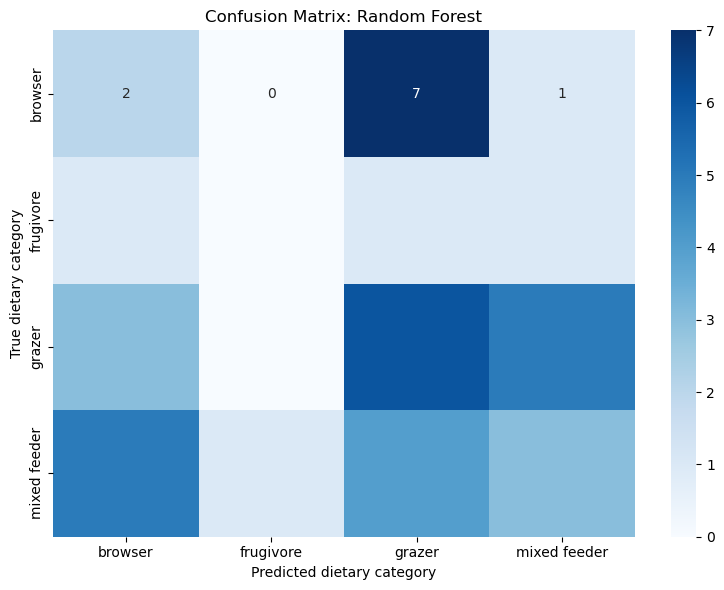

Saved: ../../results/ml_models/random_forest_confusion_matrix.png


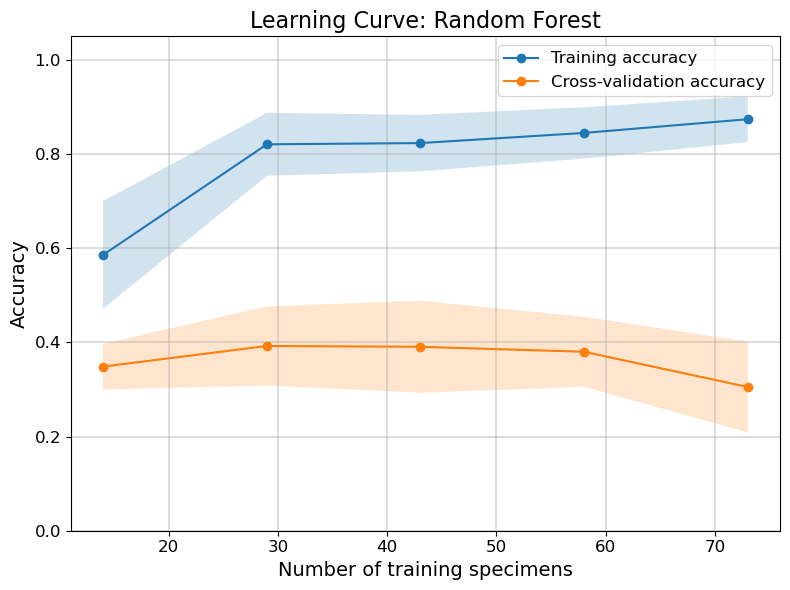

Saved: ../../results/ml_models/random_forest_learning_curve.png


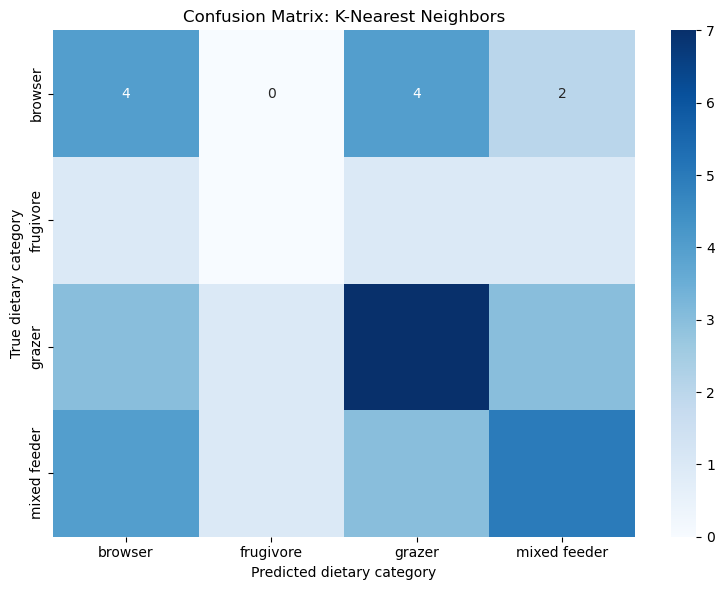

Saved: ../../results/ml_models/knearest_neighbors_confusion_matrix.png


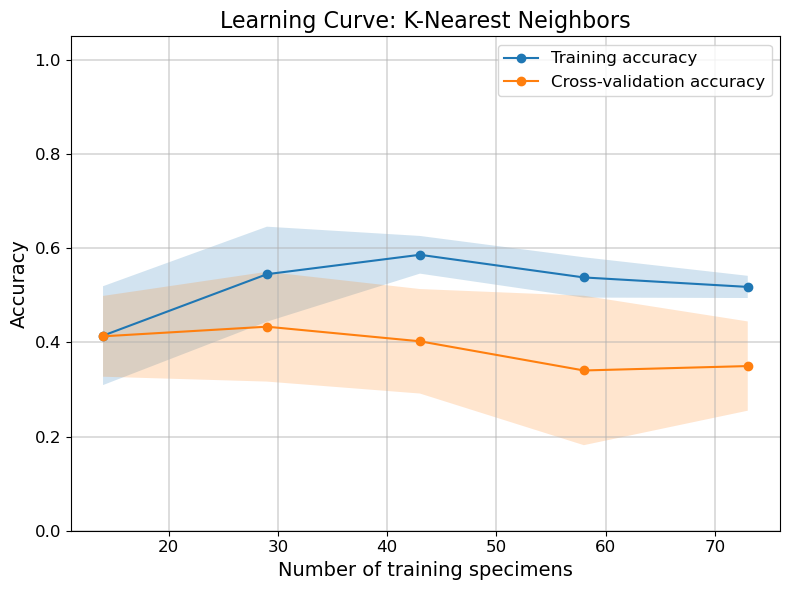

Saved: ../../results/ml_models/knearest_neighbors_learning_curve.png


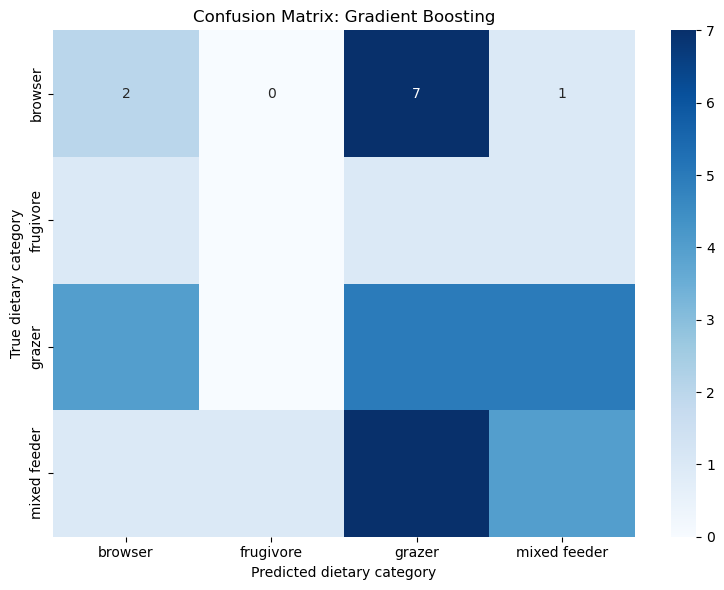

Saved: ../../results/ml_models/gradient_boosting_confusion_matrix.png


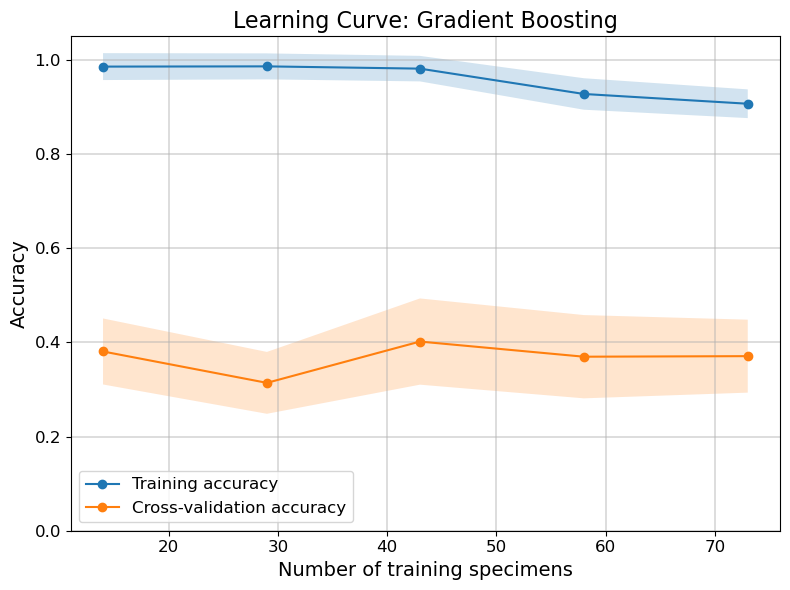

Saved: ../../results/ml_models/gradient_boosting_learning_curve.png
Shape-only confusion matrices and learning curves saved.
Run the Shape + centroid size cell (after Cell 21) to add CS results.


In [104]:
learning_curve_tables = []

# --- Shape-only models: confusion matrices and learning curves ---
for model_name, best_model in best_models.items():
    safe_name = model_name.lower().replace(" ", "_").replace("-", "")

    plot_confusion_matrix(
        confusion=all_confusion_matrices[model_name],
        model_name=model_name,
        output_path=OUTPUT_DIR / f"{safe_name}_confusion_matrix.png",
    )

    curve_df = plot_model_learning_curve(
        estimator=best_model,
        model_name=model_name,
        X_train=X_train,
        y_train=y_train,
        output_path=OUTPUT_DIR / f"{safe_name}_learning_curve.png",
    )
    curve_df.insert(0, "model", model_name)
    curve_df.insert(1, "condition", "Shape only")
    learning_curve_tables.append(curve_df)

print("Shape-only confusion matrices and learning curves saved.")
print("Run the Shape + centroid size cell (after Cell 21) to add CS results.")

## 11. Shape vs. Shape + Centroid Size (does adding size improve each ML model?)

This section answers the same question asked for LDA in the companion
`LDA_classification_workflow.ipynb` notebook, but for each of the three
machine learning models defined above (Random Forest, K-Nearest Neighbors,
Gradient Boosting): does adding centroid size (calculated from the raw,
pre-Procrustes landmark coordinates, calibrated to real-world mm units, and
natural-log transformed) improve dietary classification accuracy relative to
using the Procrustes shape coordinates alone?

To keep this an apples-to-apples comparison with the shape-only models fit
above:
- The **same** train/test split (`X_train`/`X_test`, `y_train`/`y_test`) is reused.
- The **same** `PCA_N_COMPONENTS`, `cv`, and `GridSearchCV` parameter grids are
  reused for the shape part of each shape+size model, so any accuracy change
  reflects the addition of centroid size rather than a different PCA setting
  or a different tuning search.
- PCA is fit only on the shape (coordinate) columns; centroid size is scaled
  but not projected through PCA, then both are passed to the classifier.
- The existing `evaluate_model` function is reused unchanged, so the
  shape+size results are computed with exactly the same evaluation logic
  (same metrics, same confusion matrix, same misclassification table format)
  as the shape-only results above.


In [27]:
# -----------------------------
# Shape vs. Shape + Centroid Size: build the CS-augmented feature tables
# -----------------------------

def _normalize_column_name(name: str) -> str:
    return re.sub(r"[^a-z0-9]", "", str(name).lower())


_cs_aliases = [
    "ln_centroid_size_mm", "ln centroid size mm", "log_centroid_size_mm",
    "logcentroidsizemm", "lncsmm",
]
_normalized_lookup = {_normalize_column_name(col): col for col in data.columns}
_matched_cs_column = None
for alias in _cs_aliases:
    normalized_alias = _normalize_column_name(alias)
    if normalized_alias in _normalized_lookup:
        _matched_cs_column = _normalized_lookup[normalized_alias]
        break

if _matched_cs_column is None:
    raise ValueError(
        "No ln(centroid size, mm-calibrated) column was found in the loaded "
        f"data. Available columns: {list(data.columns)}\n"
        "Run the updated GPA notebook first -- it carries this column through "
        "to procrustes_aligned_coordinates.csv either by passing through a "
        "precomputed column from your raw data, or by computing it from a "
        "raw mm-per-pixel scale factor."
    )

CS_COLUMN = _matched_cs_column
print(f"Using '{CS_COLUMN}' as the centroid size column for the shape+size models.")

X_train_cs = X_train.copy()
X_train_cs[CS_COLUMN] = data.loc[X_train.index, CS_COLUMN].to_numpy()

X_test_cs = X_test.copy()
X_test_cs[CS_COLUMN] = data.loc[X_test.index, CS_COLUMN].to_numpy()

# -----------------------------
# Shape + Centroid Size model definitions
# -----------------------------
# Same classifiers, same tuning grids, same PCA_N_COMPONENTS as the shape-only
# models above. The only difference: PCA is applied only to the shape
# (coordinate) columns via a ColumnTransformer, and centroid size gets its own
# StandardScaler and is passed to the classifier alongside the PC scores.
# The final pipeline step is still named "classifier", so the existing
# param grids (which reference "classifier__...") work unchanged.

model_definitions_cs = {
    "Random Forest": {
        "pipeline": Pipeline(
            steps=[
                ("preprocessor", ColumnTransformer(transformers=[
                    ("shape", Pipeline(steps=[
                        ("scaler", StandardScaler()),
                        ("pca", PCA(n_components=PCA_N_COMPONENTS)),
                    ]), coordinate_columns),
                    ("size", StandardScaler(), [CS_COLUMN]),
                ])),
                ("classifier", RandomForestClassifier(random_state=RANDOM_STATE)),
            ]
        ),
        "param_grid": model_definitions["Random Forest"]["param_grid"],
    },
    "K-Nearest Neighbors": {
        "pipeline": Pipeline(
            steps=[
                ("preprocessor", ColumnTransformer(transformers=[
                    ("shape", Pipeline(steps=[
                        ("scaler", StandardScaler()),
                        ("pca", PCA(n_components=PCA_N_COMPONENTS)),
                    ]), coordinate_columns),
                    ("size", StandardScaler(), [CS_COLUMN]),
                ])),
                ("classifier", KNeighborsClassifier()),
            ]
        ),
        "param_grid": model_definitions["K-Nearest Neighbors"]["param_grid"],
    },
    "Gradient Boosting": {
        "pipeline": Pipeline(
            steps=[
                ("preprocessor", ColumnTransformer(transformers=[
                    ("shape", Pipeline(steps=[
                        ("scaler", StandardScaler()),
                        ("pca", PCA(n_components=PCA_N_COMPONENTS)),
                    ]), coordinate_columns),
                    ("size", StandardScaler(), [CS_COLUMN]),
                ])),
                ("classifier", GradientBoostingClassifier(random_state=RANDOM_STATE)),
            ]
        ),
        "param_grid": model_definitions["Gradient Boosting"]["param_grid"],
    },
}

print("Shape + centroid size models prepared:")
for model_name in model_definitions_cs:
    print(f"- {model_name}")


Using 'ln_centroid_size_mm' as the centroid size column for the shape+size models.
Shape + centroid size models prepared:
- Random Forest
- K-Nearest Neighbors
- Gradient Boosting


In [28]:
# -----------------------------
# Run tuning and evaluation for the shape + centroid size models
# -----------------------------
# Reuses the same evaluate_model() function used for the shape-only models,
# so the shape+CS results are computed with identical logic/metrics.

all_results_cs = []
all_reports_cs = {}
all_misclassified_cs = []
all_confusion_matrices_cs = {}
best_models_cs = {}

for model_name, model_info in model_definitions_cs.items():
    result, report_df, misclassified_df, confusion, best_model = evaluate_model(
        model_name=f"{model_name} (Shape + CS)",
        pipeline=model_info["pipeline"],
        param_grid=model_info["param_grid"],
        X_train=X_train_cs,
        y_train=y_train,
        X_test=X_test_cs,
        y_test=y_test,
        test_indices=test_indices,
    )

    all_results_cs.append(result)
    all_reports_cs[model_name] = report_df
    all_confusion_matrices_cs[model_name] = confusion
    best_models_cs[model_name] = best_model

    if not misclassified_df.empty:
        all_misclassified_cs.append(misclassified_df)

results_cs_df = pd.DataFrame(all_results_cs)
metric_summary_cs = display_metric_summary(results_cs_df)

display(metric_summary_cs)



Evaluating Random Forest (Shape + CS)
Best parameters: {'classifier__max_depth': None, 'classifier__max_features': 'sqrt', 'classifier__min_samples_leaf': 2, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 100}
CV mean accuracy: 0.436
Training accuracy: 1.000
Test accuracy: 0.400
Weighted F1: 0.389
ROC AUC: 0.656

Evaluating K-Nearest Neighbors (Shape + CS)
Best parameters: {'classifier__metric': 'euclidean', 'classifier__n_neighbors': 7, 'classifier__weights': 'uniform'}
CV mean accuracy: 0.350
Training accuracy: 0.511
Test accuracy: 0.325
Weighted F1: 0.316
ROC AUC: 0.560

Evaluating Gradient Boosting (Shape + CS)
Best parameters: {'classifier__learning_rate': 0.01, 'classifier__max_depth': 5, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 100}
CV mean accuracy: 0.502
Training accuracy: 1.000
Test accuracy: 0.300
Weighted F1: 0.296
ROC AUC: 0.519


,model,cv_mean_accuracy,cv_sd_accuracy,train_accuracy,test_accuracy,balanced_accuracy,precision_weighted,recall_weighted,f1_weighted,roc_auc_macro_ovr
0,Random Forest (Shape + CS),0.436257,0.126178,1.00000,0.400,0.321154,0.387786,0.400,0.389165,0.656178
1,K-Nearest Neighbors (Shape + CS),0.350292,0.108343,0.51087,0.325,0.253297,0.323750,0.325,0.316029,0.560293
2,Gradient Boosting (Shape + CS),0.501754,0.128690,1.00000,0.300,0.246978,0.333333,0.300,0.296482,0.519477


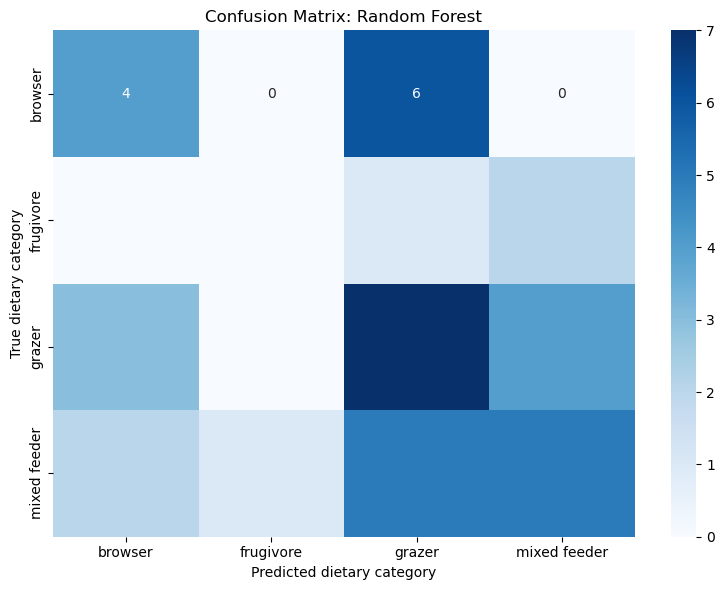

Saved: ../../results/ml_models/random_forest_confusion_matrix.png


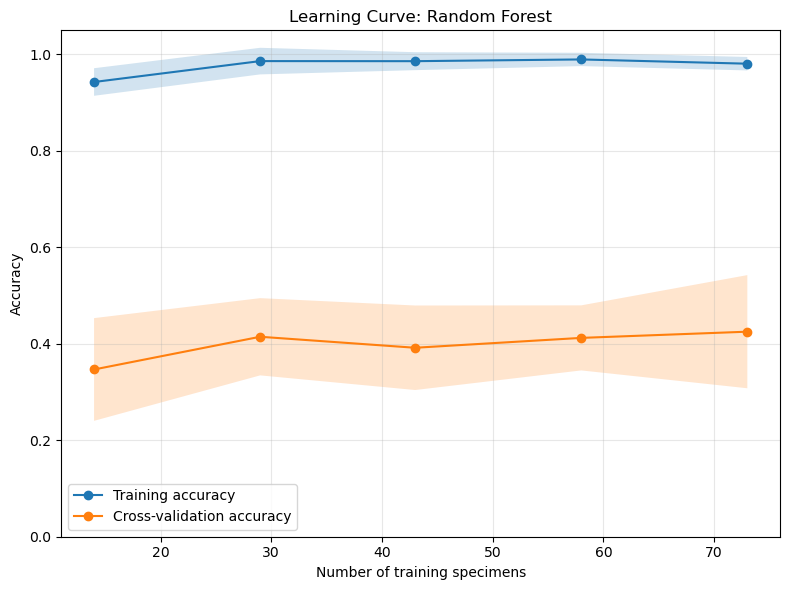

Saved: ../../results/ml_models/random_forest_learning_curve.png


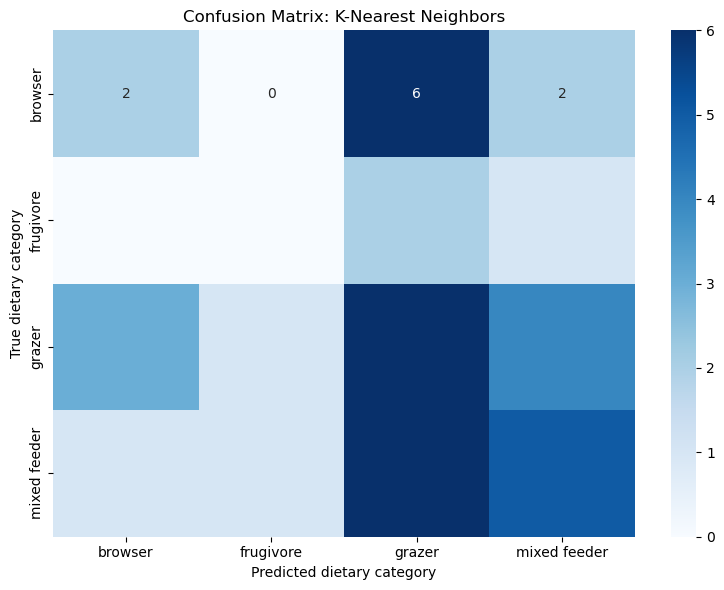

Saved: ../../results/ml_models/knearest_neighbors_confusion_matrix.png


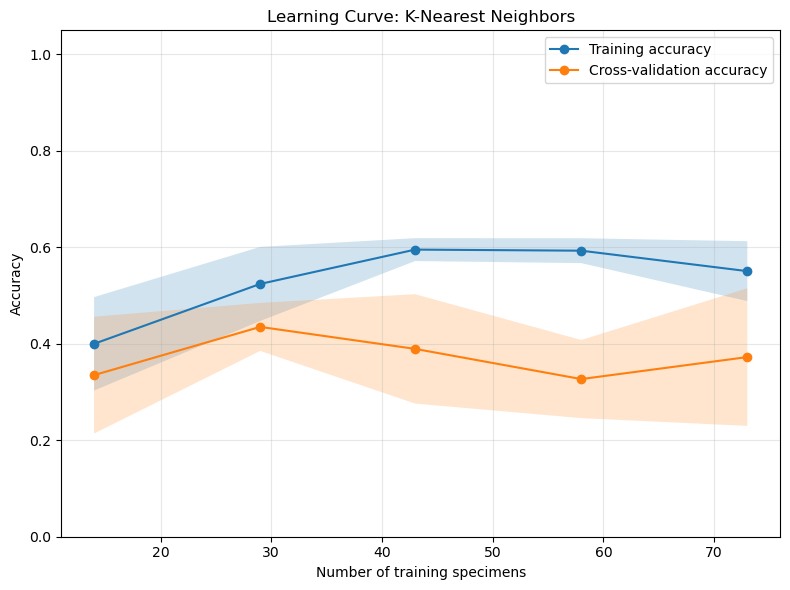

Saved: ../../results/ml_models/knearest_neighbors_learning_curve.png


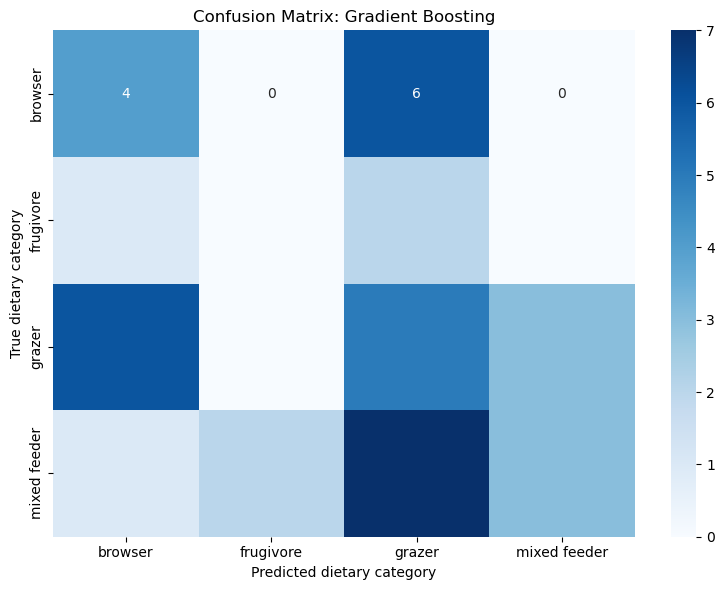

Saved: ../../results/ml_models/gradient_boosting_confusion_matrix.png


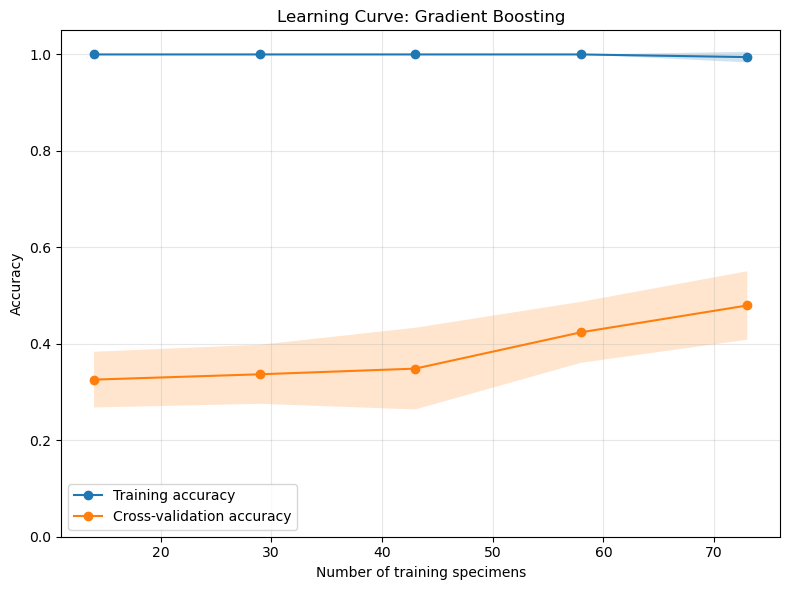

Saved: ../../results/ml_models/gradient_boosting_learning_curve.png
Saved: ../../results/ml_models/ml_learning_curve_values.csv


In [29]:
# -----------------------------
# Shape + centroid size models: confusion matrices and learning curves
# -----------------------------
# This cell runs AFTER Cell 21 so that best_models_cs is already populated.

for model_name, best_model in best_models_cs.items():
    safe_name = (
        model_name.lower()
        .replace(" ", "_")
        .replace("-", "")
        .replace("(", "")
        .replace(")", "")
    )

    # Strip the "(Shape + CS)" suffix to look up the confusion matrix,
    # which is keyed by the base model name in all_confusion_matrices_cs.
    base_name = model_name.replace(" (Shape + CS)", "")

    plot_confusion_matrix(
        confusion=all_confusion_matrices_cs[base_name],
        model_name=model_name,
        output_path=OUTPUT_DIR / f"{safe_name}_confusion_matrix.png",
    )

    curve_df = plot_model_learning_curve(
        estimator=best_model,
        model_name=model_name,
        X_train=X_train_cs,
        y_train=y_train,
        output_path=OUTPUT_DIR / f"{safe_name}_learning_curve.png",
    )
    curve_df.insert(0, "model", model_name)
    curve_df.insert(1, "condition", "Shape + centroid size")
    learning_curve_tables.append(curve_df)

# Save the combined learning curve table (shape-only + shape+CS).
learning_curves_df = pd.concat(learning_curve_tables, ignore_index=True)
learning_curves_path = OUTPUT_DIR / "ml_learning_curve_values.csv"
learning_curves_df.to_csv(learning_curves_path, index=False)
print(f"Saved: {learning_curves_path}")

Shape-only vs. Shape + centroid size, all models
-------------------------------------------------


,model,condition,cv_mean_accuracy,cv_sd_accuracy,test_accuracy,test_balanced_accuracy,test_f1_weighted,test_roc_auc_macro_ovr,delta_test_accuracy_vs_shape_only
0,Random Forest,Shape only,0.349708,0.121556,0.275,0.214835,0.263652,0.540832,0.125
1,Random Forest,Shape + centroid size,0.436257,0.126178,0.400,0.321154,0.389165,0.656178,0.125
2,K-Nearest Neighbors,Shape only,0.349708,0.117987,0.400,0.321154,0.395291,0.618798,-0.075
3,K-Nearest Neighbors,Shape + centroid size,0.350292,0.108343,0.325,0.253297,0.316029,0.560293,-0.075
4,Gradient Boosting,Shape only,0.392982,0.117143,0.275,0.216209,0.266830,0.490169,0.025
5,Gradient Boosting,Shape + centroid size,0.501754,0.128690,0.300,0.246978,0.296482,0.519477,0.025



Saved: ../../results/ml_models/ml_shape_vs_shape_cs_comparison.csv
Saved: ../../results/ml_models/ml_shape_cs_model_performance_summary.csv
Saved: ../../results/ml_models/random_forest_shape_cs_classification_report.csv
Saved: ../../results/ml_models/random_forest_shape_cs_confusion_matrix.csv
Saved: ../../results/ml_models/knearest_neighbors_shape_cs_classification_report.csv
Saved: ../../results/ml_models/knearest_neighbors_shape_cs_confusion_matrix.csv
Saved: ../../results/ml_models/gradient_boosting_shape_cs_classification_report.csv
Saved: ../../results/ml_models/gradient_boosting_shape_cs_confusion_matrix.csv
Saved: ../../results/ml_models/ml_shape_cs_misclassified_specimens.csv


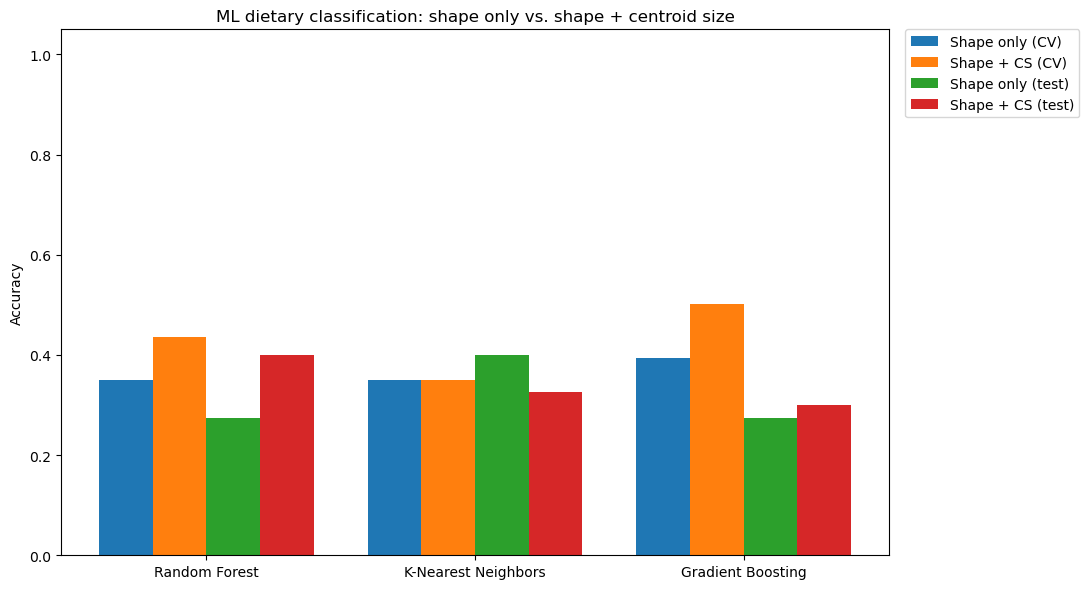

Saved: ../../results/ml_models/ml_shape_vs_shape_cs_comparison.png


In [30]:
# -----------------------------
# Combined comparison table: shape-only vs. shape + centroid size
# -----------------------------

comparison_rows = []
for model_name in model_definitions.keys():
    shape_only_row = results_df.loc[results_df["model"] == model_name].iloc[0]
    shape_cs_row = results_cs_df.loc[
        results_cs_df["model"] == f"{model_name} (Shape + CS)"
    ].iloc[0]

    comparison_rows.append({
        "model": model_name,
        "condition": "Shape only",
        "cv_mean_accuracy": shape_only_row["cv_mean_accuracy"],
        "cv_sd_accuracy": shape_only_row["cv_sd_accuracy"],
        "test_accuracy": shape_only_row["test_accuracy"],
        "test_balanced_accuracy": shape_only_row["balanced_accuracy"],
        "test_f1_weighted": shape_only_row["f1_weighted"],
        "test_roc_auc_macro_ovr": shape_only_row["roc_auc_macro_ovr"],
    })
    comparison_rows.append({
        "model": model_name,
        "condition": "Shape + centroid size",
        "cv_mean_accuracy": shape_cs_row["cv_mean_accuracy"],
        "cv_sd_accuracy": shape_cs_row["cv_sd_accuracy"],
        "test_accuracy": shape_cs_row["test_accuracy"],
        "test_balanced_accuracy": shape_cs_row["balanced_accuracy"],
        "test_f1_weighted": shape_cs_row["f1_weighted"],
        "test_roc_auc_macro_ovr": shape_cs_row["roc_auc_macro_ovr"],
    })

shape_vs_shape_cs_comparison_df = pd.DataFrame(comparison_rows)

# Delta = shape+CS test accuracy minus shape-only test accuracy, per model.
delta_lookup = (
    shape_vs_shape_cs_comparison_df
    .pivot(index="model", columns="condition", values="test_accuracy")
    .assign(delta_test_accuracy=lambda d: d["Shape + centroid size"] - d["Shape only"])
    ["delta_test_accuracy"]
)
shape_vs_shape_cs_comparison_df["delta_test_accuracy_vs_shape_only"] = (
    shape_vs_shape_cs_comparison_df["model"].map(delta_lookup)
)

print("Shape-only vs. Shape + centroid size, all models")
print("-------------------------------------------------")
display(shape_vs_shape_cs_comparison_df)

comparison_path = OUTPUT_DIR / "ml_shape_vs_shape_cs_comparison.csv"
shape_vs_shape_cs_comparison_df.to_csv(comparison_path, index=False)
print(f"\nSaved: {comparison_path}")

# Also save the raw shape+CS per-model outputs, mirroring the shape-only saves
# in the "Save model outputs" section above.
results_cs_path = OUTPUT_DIR / "ml_shape_cs_model_performance_summary.csv"
results_cs_df.to_csv(results_cs_path, index=False)
print(f"Saved: {results_cs_path}")

for model_name, report_df in all_reports_cs.items():
    safe_name = model_name.lower().replace(" ", "_").replace("-", "") + "_shape_cs"
    report_path = OUTPUT_DIR / f"{safe_name}_classification_report.csv"
    report_df.to_csv(report_path)
    print(f"Saved: {report_path}")

    confusion_df = pd.DataFrame(
        all_confusion_matrices_cs[model_name],
        index=label_encoder.classes_,
        columns=label_encoder.classes_,
    )
    confusion_path = OUTPUT_DIR / f"{safe_name}_confusion_matrix.csv"
    confusion_df.to_csv(confusion_path)
    print(f"Saved: {confusion_path}")

if all_misclassified_cs:
    misclassified_cs_all_df = pd.concat(all_misclassified_cs, ignore_index=True)
else:
    misclassified_cs_all_df = pd.DataFrame(
        columns=metadata_columns_present + ["true_label", "predicted_label", "correct", "model"]
    )
misclassified_cs_path = OUTPUT_DIR / "ml_shape_cs_misclassified_specimens.csv"
misclassified_cs_all_df.to_csv(misclassified_cs_path, index=False)
print(f"Saved: {misclassified_cs_path}")

# -----------------------------
# Grouped bar chart: CV and test accuracy, shape-only vs. shape+CS, all models
# -----------------------------

model_names_ordered = list(model_definitions.keys())
x_pos = np.arange(len(model_names_ordered))
width = 0.2

shape_only_cv = [results_df.loc[results_df["model"] == m, "cv_mean_accuracy"].iloc[0] for m in model_names_ordered]
shape_cs_cv = [results_cs_df.loc[results_cs_df["model"] == f"{m} (Shape + CS)", "cv_mean_accuracy"].iloc[0] for m in model_names_ordered]
shape_only_test = [results_df.loc[results_df["model"] == m, "test_accuracy"].iloc[0] for m in model_names_ordered]
shape_cs_test = [results_cs_df.loc[results_cs_df["model"] == f"{m} (Shape + CS)", "test_accuracy"].iloc[0] for m in model_names_ordered]

plt.figure(figsize=(11, 6))
plt.bar(x_pos - 1.5 * width, shape_only_cv, width, label="Shape only (CV)")
plt.bar(x_pos - 0.5 * width, shape_cs_cv, width, label="Shape + CS (CV)")
plt.bar(x_pos + 0.5 * width, shape_only_test, width, label="Shape only (test)")
plt.bar(x_pos + 1.5 * width, shape_cs_test, width, label="Shape + CS (test)")

plt.xticks(x_pos, model_names_ordered)
plt.ylabel("Accuracy")
plt.ylim(0, 1.05)
plt.title("ML dietary classification: shape only vs. shape + centroid size")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", borderaxespad=0)
plt.tight_layout()

comparison_plot_path = OUTPUT_DIR / "ml_shape_vs_shape_cs_comparison.png"
plt.savefig(comparison_plot_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved: {comparison_plot_path}")


## 10. Output summary

In [ ]:
# -----------------------------
# Final output summary
# -----------------------------

print("Machine learning workflow complete.")
print(f"\nOutputs saved to: {OUTPUT_DIR.resolve()}")
print("\nOutput files:")
for path in sorted(OUTPUT_DIR.glob("*")):
    print(f"- {path.name}")
